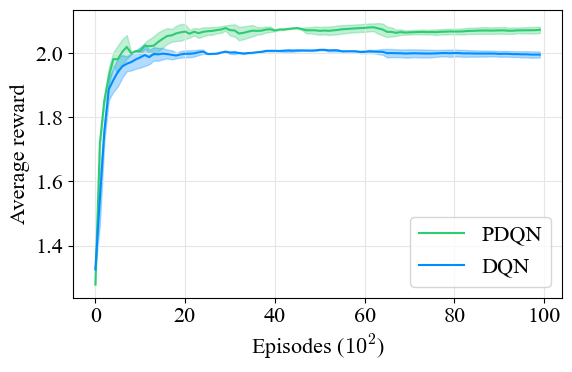

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys

def safe_convert(x):
    if isinstance(x, str):
        return float(x.strip('[]'))
    else:
        return float(x)

# reward_runs = [pd.read_csv(f'./training_results/reward_{i}.csv', header=None).iloc[:, 1].apply(safe_convert) for i in range(2)]
# Load and convert
pdqn_reward_runs = [
    pd.read_csv(f'./training_results/pdqn/reward_{i}.csv', header=None).iloc[:, 1]
    .apply(safe_convert).dropna().values[:100]  # Only take first 500 entries
    for i in range(2)
]

dqn_reward_runs = [
    pd.read_csv(f'./training_results/dqn/reward_{i}.csv', header=None).iloc[:, 1]
    .apply(safe_convert).dropna().values[:100]  # Only take first 500 entries
    for i in range(2)
]

# Stack into numpy arrays
pdqn_reward_runs = np.stack(pdqn_reward_runs)
pdqn_mean_rewards = np.mean(pdqn_reward_runs, axis=0)
pdqn_std_rewards = np.std(pdqn_reward_runs, axis=0)

dqn_reward_runs = np.stack(dqn_reward_runs)
dqn_mean_rewards = np.mean(dqn_reward_runs, axis=0)
dqn_std_rewards = np.std(dqn_reward_runs, axis=0)

timesteps = np.arange(len(pdqn_mean_rewards))

# Plotting
font = {
        'family' : 'Times New Roman',
        'weight' : 'normal', #weight or fontweight	[ 'normal' | 'bold' | 'heavy' | 'light' | 'ultrabold' | 'ultralight']
        'size'   : 16}
plt.rc('font', **font)

plt.figure(figsize=(6, 4))

# PDQN plot
plt.plot(timesteps, pdqn_mean_rewards, label="PDQN", color='#2ECC71')
plt.fill_between(timesteps, pdqn_mean_rewards - pdqn_std_rewards, pdqn_mean_rewards + pdqn_std_rewards, alpha=0.3, color='#2ECC71')

# DQN plot
plt.plot(timesteps, dqn_mean_rewards, label="DQN", color='#008DFF')
plt.fill_between(timesteps, dqn_mean_rewards - dqn_std_rewards, dqn_mean_rewards + dqn_std_rewards, alpha=0.3, color='#008DFF')

plt.xlabel('Episodes ($10^2$)')
plt.ylabel('Average reward')
plt.rcParams['mathtext.fontset'] = 'cm'
# plt.title('Reward Learning Curve')
plt.grid(color='0.90')
plt.legend()
plt.tight_layout()
# Adjust layout and save the plot
if sys.platform=='linux':
    root_pdf = r"/home/chenwu/Documents/Gitlab/catkin_ws_chen/data_analysis/pdf/results_rl_learning_v1.pdf"
else:
    root_pdf = r"C:\Users\chenwu\Documents\Gitlab\catkin_ws_chen\data_analysis\pdf\results_learning_v1.pdf"
plt.savefig(root_pdf, bbox_inches='tight')
plt.show()